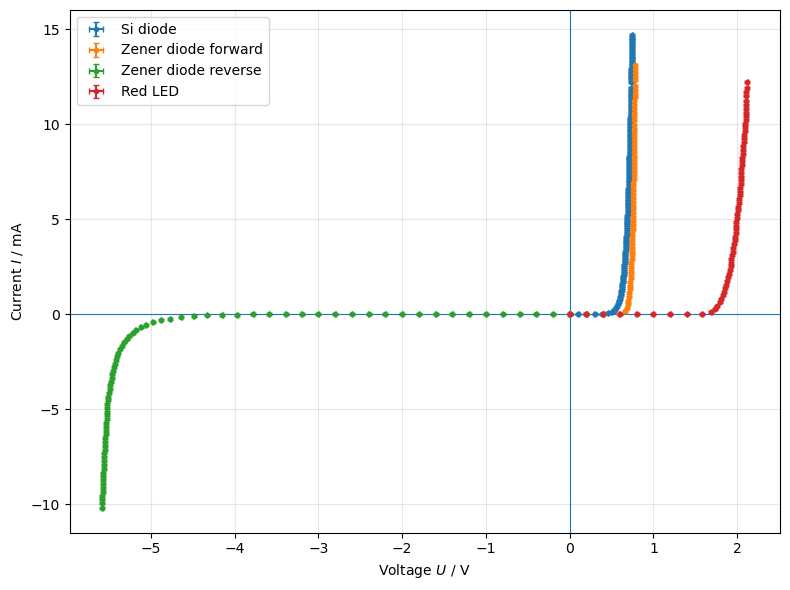


Si diode
Number of points: 152
Voltage range: -0.0005 V to 0.7450 V
Current range: 0.0001 mA to 14.7000 mA

Zener diode forward
Number of points: 69
Voltage range: -0.0004 V to 0.7780 V
Current range: 0.0000 mA to 13.1000 mA

Zener diode reverse
Number of points: 79
Voltage range: -5.5800 V to 0.0006 V
Current range: -10.2000 mA to -0.0000 mA

Red LED
Number of points: 71
Voltage range: -0.0007 V to 2.1200 V
Current range: 0.0000 mA to 12.2000 mA

Saved figure as: task1_combined_IV_plot.png


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

si_file = "Task 1 Si Diode.csv"
zener_forward_file = "Task 1 Zener forward.csv"
zener_reverse_file = "Task 1 Zener reverse.csv"
led_file = "Task 1 red LED.csv"

dU = 0.005      # V
dI = 0.05       # mA

def read_task1_csv(filename):
    df = pd.read_csv(filename)

    I_raw = pd.to_numeric(df.iloc[:, 0].astype(str).str.replace(",", ".", regex=False), errors="coerce")
    U_raw = pd.to_numeric(df.iloc[:, 1].astype(str).str.replace(",", ".", regex=False), errors="coerce")

    mask = np.isfinite(I_raw) & np.isfinite(U_raw)
    I_raw = I_raw[mask].to_numpy()
    U_raw = U_raw[mask].to_numpy()

    # The CSV values are stored as microampere and microvolt
    I_mA = I_raw / 1000       # microampere to milliampere
    U_V = U_raw / 1e6         # microvolt to volt

    return U_V, I_mA

U_si, I_si = read_task1_csv(si_file)
U_zf, I_zf = read_task1_csv(zener_forward_file)
U_zr, I_zr = read_task1_csv(zener_reverse_file)
U_led, I_led = read_task1_csv(led_file)

# Zener reverse branch: measured positive, plotted negative
U_zr = -U_zr
I_zr = -I_zr

plt.figure(figsize=(8, 6))

plt.errorbar(U_si, I_si, xerr=dU, yerr=dI, fmt="o", markersize=3, capsize=2, label="Si diode")
plt.errorbar(U_zf, I_zf, xerr=dU, yerr=dI, fmt="o", markersize=3, capsize=2, label="Zener diode forward")
plt.errorbar(U_zr, I_zr, xerr=dU, yerr=dI, fmt="o", markersize=3, capsize=2, label="Zener diode reverse")
plt.errorbar(U_led, I_led, xerr=dU, yerr=dI, fmt="o", markersize=3, capsize=2, label="Red LED")

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel(r"Voltage $U$ / V")
plt.ylabel(r"Current $I$ / mA")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("task1_combined_IV_plot.png", dpi=300)
plt.show()

datasets = {
    "Si diode": (U_si, I_si),
    "Zener diode forward": (U_zf, I_zf),
    "Zener diode reverse": (U_zr, I_zr),
    "Red LED": (U_led, I_led)
}

for name, (U, I) in datasets.items():
    print(f"\n{name}")
    print(f"Number of points: {len(U)}")
    print(f"Voltage range: {U.min():.4f} V to {U.max():.4f} V")
    print(f"Current range: {I.min():.4f} mA to {I.max():.4f} mA")

print("\nSaved figure as: task1_combined_IV_plot.png")

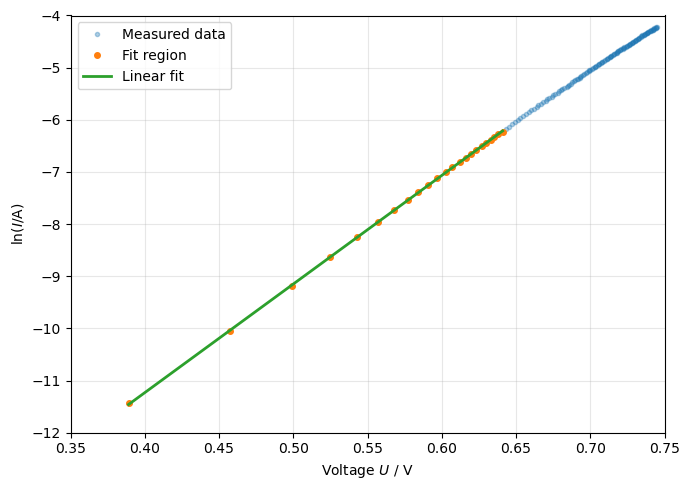

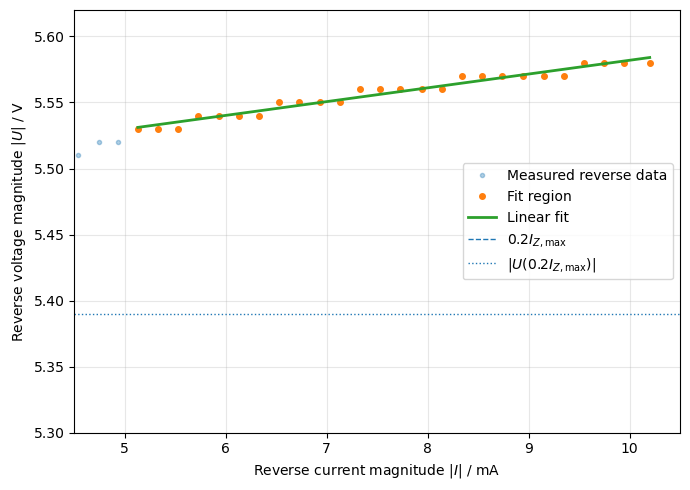

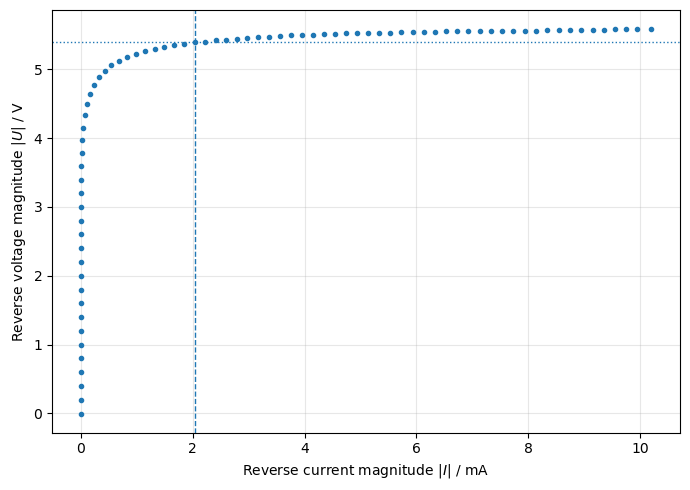

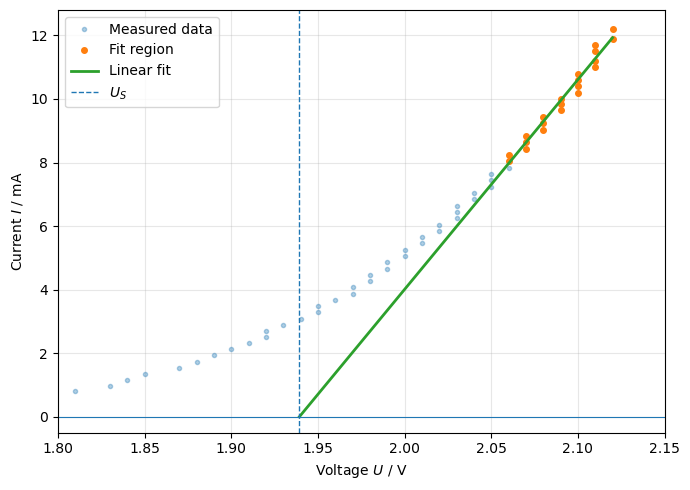

========== Task 2 Results ==========

--- Si diode ---
T = 293.15 K
U_T = 25.262 mV
Fit interval: 0.005 mA < I < 2 mA
m = 2.0821e+01 ± 3.7672e-02 1/V
b = -1.9558e+01 ± 2.2026e-02
n = 1.901 ± 0.003

--- Zener diode ---
Fit interval: |I| > 5 mA
I_Z,max = 10.200 mA
0.2 I_Z,max = 2.040 mA
|U| at 0.2 I_Z,max = 5.390 V
U_Z = 5.478 ± 0.003 V
R = 2642.2 ± 64.8 ohm
r_d = 10.4 ± 0.4 ohm

--- Red LED ---
Fit interval: I > 8 mA
a = 6.5992e+01 ± 2.7228e+00 mA/V
b = -1.2797e+02 ± 5.6947e+00 mA
U_S = 1.939 ± 0.006 V
lambda = 639 ± 2 nm

Saved figures:
task2_si_semilog_fit_clean.png
task2_zener_reverse_fit_clean.png
task2_zener_reverse_full_clean.png
task2_led_threshold_fit_clean.png


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import k, e, h, c

si_file = "Task 1 Si Diode.csv"
zener_reverse_file = "Task 1 Zener reverse.csv"
led_file = "Task 1 red LED.csv"

T = 293.15                 # K, assumed room temperature
U_T = k * T / e            # thermal voltage in V

dU = 0.005                 # V
dI_mA = 0.05               # mA

si_fit_I_min_mA = 0.005
si_fit_I_max_mA = 2.0

zener_fit_I_min_mA = 5.0

led_fit_I_min_mA = 8.0

def read_task1_csv(filename):
    df = pd.read_csv(filename)

    I_raw = pd.to_numeric(
        df.iloc[:, 0].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )
    U_raw = pd.to_numeric(
        df.iloc[:, 1].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

    mask = np.isfinite(I_raw) & np.isfinite(U_raw)
    I_raw = I_raw[mask].to_numpy()
    U_raw = U_raw[mask].to_numpy()

    # CSV values are stored as microampere and microvolt
    I_mA = I_raw / 1000.0
    U_V = U_raw / 1e6

    return U_V, I_mA

U_si, I_si_mA = read_task1_csv(si_file)

U_zr_raw, I_zr_raw_mA = read_task1_csv(zener_reverse_file)

# Zener reverse data are treated as magnitudes for parameter extraction
U_zr_abs = U_zr_raw
I_zr_abs_mA = I_zr_raw_mA

U_led, I_led_mA = read_task1_csv(led_file)

si_mask = (
    (I_si_mA > si_fit_I_min_mA) &
    (I_si_mA < si_fit_I_max_mA) &
    (I_si_mA > 0)
)

U_si_fit = U_si[si_mask]
I_si_fit_mA = I_si_mA[si_mask]

lnI_si = np.log(np.clip(I_si_mA * 1e-3, 1e-30, None))
lnI_si_fit = np.log(I_si_fit_mA * 1e-3)

# Linear fit: ln(I) = m U + b
si_coeff, si_cov = np.polyfit(U_si_fit, lnI_si_fit, deg=1, cov=True)
m_si, b_si = si_coeff
dm_si, db_si = np.sqrt(np.diag(si_cov))

n_si = 1 / (m_si * U_T)
dn_si = n_si * dm_si / abs(m_si)

U_si_line = np.linspace(U_si_fit.min(), U_si_fit.max(), 300)
lnI_si_line = m_si * U_si_line + b_si

plt.figure(figsize=(7, 5))

plt.plot(U_si, lnI_si, "o", markersize=3, alpha=0.35, label="Measured data")
plt.plot(U_si_fit, lnI_si_fit, "o", markersize=4, label="Fit region")
plt.plot(U_si_line, lnI_si_line, linewidth=2, label="Linear fit")

plt.xlabel(r"Voltage $U$ / V")
plt.ylabel(r"$\ln(I/\mathrm{A})$")
plt.xlim(0.35, 0.75)
plt.ylim(-12.0, -4.0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("task2_si_semilog_fit_clean.png", dpi=300)
plt.show()

zener_mask = I_zr_abs_mA > zener_fit_I_min_mA

I_z_fit_A = I_zr_abs_mA[zener_mask] * 1e-3
U_z_fit = U_zr_abs[zener_mask]

# Linear fit: |U| = a |I| + b, I in A
z_coeff, z_cov = np.polyfit(I_z_fit_A, U_z_fit, deg=1, cov=True)
a_z, b_z = z_coeff
da_z, db_z = np.sqrt(np.diag(z_cov))

# Differential resistance
rd_z = a_z
drd_z = da_z

# Breakdown voltage from intercept
Uz = b_z
dUz = db_z

# Evaluation current
Iz_max_mA = np.max(I_zr_abs_mA)
Iz_eval_mA = 0.2 * Iz_max_mA
Iz_eval_A = Iz_eval_mA * 1e-3

# Voltage at 0.2 I_Z,max from interpolation
sort_idx = np.argsort(I_zr_abs_mA)
I_sorted_mA = I_zr_abs_mA[sort_idx]
U_sorted_abs = U_zr_abs[sort_idx]

U_eval_abs = np.interp(Iz_eval_mA, I_sorted_mA, U_sorted_abs)

# Direct current resistance
R_z = U_eval_abs / Iz_eval_A

dI_A = dI_mA * 1e-3
dR_z = R_z * np.sqrt((dU / U_eval_abs)**2 + (dI_A / Iz_eval_A)**2)

# Fit line for Zener plot
I_z_line_A = np.linspace(I_z_fit_A.min(), I_z_fit_A.max(), 300)
U_z_line = a_z * I_z_line_A + b_z

plt.figure(figsize=(7, 5))

plt.plot(
    I_zr_abs_mA,
    U_zr_abs,
    "o",
    markersize=3,
    alpha=0.35,
    label="Measured reverse data"
)

plt.plot(
    I_zr_abs_mA[zener_mask],
    U_zr_abs[zener_mask],
    "o",
    markersize=4,
    label="Fit region"
)

plt.plot(
    I_z_line_A * 1e3,
    U_z_line,
    linewidth=2,
    label="Linear fit"
)

plt.axvline(
    Iz_eval_mA,
    linestyle="--",
    linewidth=1,
    label=r"$0.2I_{Z,\max}$"
)

plt.axhline(
    U_eval_abs,
    linestyle=":",
    linewidth=1,
    label=r"$|U(0.2I_{Z,\max})|$"
)

plt.xlabel(r"Reverse current magnitude $|I|$ / mA")
plt.ylabel(r"Reverse voltage magnitude $|U|$ / V")
plt.xlim(4.5, 10.5)
plt.ylim(5.30, 5.62)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("task2_zener_reverse_fit_clean.png", dpi=300)
plt.show()

# Optional full reverse curve
plt.figure(figsize=(7, 5))

plt.plot(I_zr_abs_mA, U_zr_abs, "o", markersize=3)
plt.axvline(Iz_eval_mA, linestyle="--", linewidth=1)
plt.axhline(U_eval_abs, linestyle=":", linewidth=1)

plt.xlabel(r"Reverse current magnitude $|I|$ / mA")
plt.ylabel(r"Reverse voltage magnitude $|U|$ / V")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("task2_zener_reverse_full_clean.png", dpi=300)
plt.show()

led_mask = I_led_mA > led_fit_I_min_mA

U_led_fit = U_led[led_mask]
I_led_fit_mA = I_led_mA[led_mask]

# Linear fit: I = aU + b, I in mA
led_coeff, led_cov = np.polyfit(U_led_fit, I_led_fit_mA, deg=1, cov=True)
a_led, b_led = led_coeff
da_led, db_led = np.sqrt(np.diag(led_cov))
cov_ab_led = led_cov[0, 1]

U_S = -b_led / a_led

# Uncertainty of U_S including covariance
dUS_da = b_led / (a_led**2)
dUS_db = -1 / a_led
dU_S = np.sqrt(
    (dUS_da * da_led)**2 +
    (dUS_db * db_led)**2 +
    2 * dUS_da * dUS_db * cov_ab_led
)

lambda_nm = (h * c / (e * U_S)) * 1e9
dlambda_nm = lambda_nm * dU_S / U_S

# Fit line from threshold to maximum fitted data
U_led_line = np.linspace(U_S, U_led_fit.max(), 300)
I_led_line_mA = a_led * U_led_line + b_led

plt.figure(figsize=(7, 5))

plt.plot(U_led, I_led_mA, "o", markersize=3, alpha=0.35, label="Measured data")
plt.plot(U_led_fit, I_led_fit_mA, "o", markersize=4, label="Fit region")
plt.plot(U_led_line, I_led_line_mA, linewidth=2, label="Linear fit")
plt.axvline(U_S, linestyle="--", linewidth=1, label=r"$U_S$")
plt.axhline(0, linewidth=0.8)

plt.xlabel(r"Voltage $U$ / V")
plt.ylabel(r"Current $I$ / mA")
plt.xlim(1.80, 2.15)
plt.ylim(-0.5, 12.8)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("task2_led_threshold_fit_clean.png", dpi=300)
plt.show()

print("========== Task 2 Results ==========")

print("\n--- Si diode ---")
print(f"T = {T:.2f} K")
print(f"U_T = {U_T*1e3:.3f} mV")
print(f"Fit interval: {si_fit_I_min_mA:.4g} mA < I < {si_fit_I_max_mA:.4g} mA")
print(f"m = {m_si:.4e} ± {dm_si:.4e} 1/V")
print(f"b = {b_si:.4e} ± {db_si:.4e}")
print(f"n = {n_si:.3f} ± {dn_si:.3f}")

print("\n--- Zener diode ---")
print(f"Fit interval: |I| > {zener_fit_I_min_mA:.4g} mA")
print(f"I_Z,max = {Iz_max_mA:.3f} mA")
print(f"0.2 I_Z,max = {Iz_eval_mA:.3f} mA")
print(f"|U| at 0.2 I_Z,max = {U_eval_abs:.3f} V")
print(f"U_Z = {Uz:.3f} ± {dUz:.3f} V")
print(f"R = {R_z:.1f} ± {dR_z:.1f} ohm")
print(f"r_d = {rd_z:.1f} ± {drd_z:.1f} ohm")

print("\n--- Red LED ---")
print(f"Fit interval: I > {led_fit_I_min_mA:.4g} mA")
print(f"a = {a_led:.4e} ± {da_led:.4e} mA/V")
print(f"b = {b_led:.4e} ± {db_led:.4e} mA")
print(f"U_S = {U_S:.3f} ± {dU_S:.3f} V")
print(f"lambda = {lambda_nm:.0f} ± {dlambda_nm:.0f} nm")

print("\nSaved figures:")
print("task2_si_semilog_fit_clean.png")
print("task2_zener_reverse_fit_clean.png")
print("task2_zener_reverse_full_clean.png")
print("task2_led_threshold_fit_clean.png")

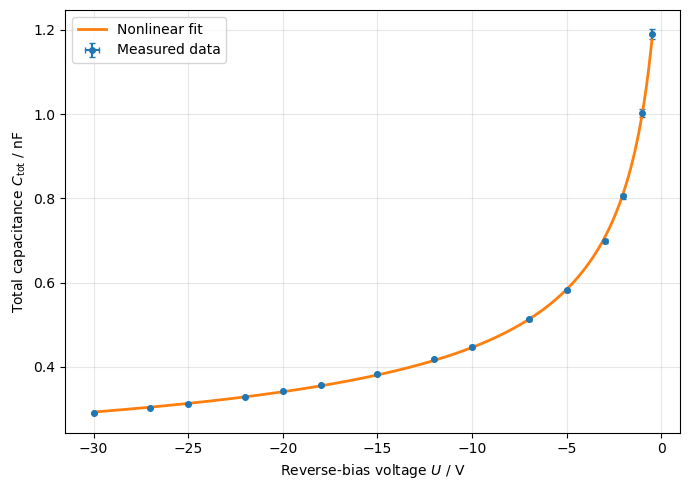

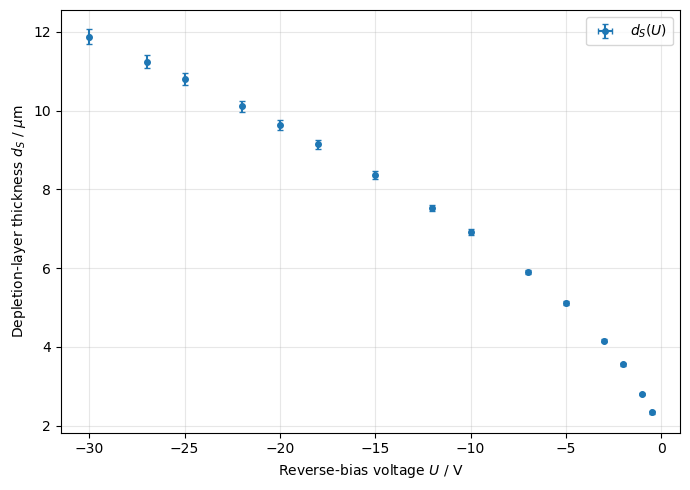

========== Task 3 Processed Data ==========
 U_reverse_bias_V   f_kHz  C_tot_nF  dC_tot_freq_nF  C_S_nF  d_S_um
          -0.5000  9.8389    1.1894          0.0121  1.1186  2.3350
          -1.0000 10.7179    1.0023          0.0094  0.9315  2.8040
          -2.0000 11.9629    0.8045          0.0067  0.7338  3.5597
          -3.0000 12.8382    0.6986          0.0054  0.6278  4.1606
          -5.0000 14.0736    0.5813          0.0041  0.5105  5.1162
          -7.0000 14.9786    0.5132          0.0034  0.4424  5.9040
         -10.0000 16.0286    0.4482          0.0028  0.3774  6.9215
         -12.0000 16.6026    0.4177          0.0025  0.3469  7.5290
         -15.0000 17.3417    0.3829          0.0022  0.3121  8.3697
         -18.0000 17.9757    0.3563          0.0020  0.2855  9.1473
         -20.0000 18.3557    0.3417          0.0019  0.2709  9.6403
         -22.0000 18.7087    0.3290          0.0018  0.2582 10.1172
         -25.0000 19.1917    0.3126          0.0016  0.2418 10.8012
    

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.constants import epsilon_0

task3_file = "Task 3.csv"

L = 220e-3                 # H
dL_rel = 0.05              # 5 percent systematic uncertainty

epsilon_r = 11.8           # relative permittivity of silicon
A = 25e-6                  # m^2, because 25 mm^2 = 25e-6 m^2

df_kHz = 0.05              # kHz, resonance frequency uncertainty
df_Hz = df_kHz * 1e3       # Hz

dU = 0.01                  # V

df = pd.read_csv(task3_file)

U_supply = pd.to_numeric(
    df.iloc[:, 0].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
)

f_kHz = pd.to_numeric(
    df.iloc[:, 1].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
)

mask = np.isfinite(U_supply) & np.isfinite(f_kHz)
U_supply = U_supply[mask].to_numpy()
f_kHz = f_kHz[mask].to_numpy()

U = -U_supply              # V, reverse-bias diode voltage
f_Hz = f_kHz * 1e3         # Hz

C_tot = 1 / ((2 * np.pi * f_Hz)**2 * L)      # F
C_tot_nF = C_tot * 1e9                       # nF

# Random uncertainty from frequency only:
# dC/C = 2 df/f
dC_freq = C_tot * 2 * df_Hz / f_Hz
dC_freq_nF = dC_freq * 1e9

# Systematic uncertainty from L:
# dC/C = dL/L
dC_L_sys = C_tot * dL_rel
dC_L_sys_nF = dC_L_sys * 1e9

def capacitance_model(U, C_G, C_0, U_D):
    return C_G + C_0 * np.sqrt(U_D / (U_D - U))

p0 = [0.08, 1.45, 0.65]

bounds = ([0.0, 0.0, 0.01], [5.0, 10.0, 5.0])

popt, pcov = curve_fit(
    capacitance_model,
    U,
    C_tot_nF,
    p0=p0,
    sigma=dC_freq_nF,
    absolute_sigma=True,
    bounds=bounds,
    maxfev=10000
)

C_G_nF, C_0_nF, U_D = popt
dC_G_nF, dC_0_nF, dU_D = np.sqrt(np.diag(pcov))

# Fit curve
U_fit = np.linspace(U.min(), U.max(), 500)
U_fit = np.sort(U_fit)
C_fit_nF = capacitance_model(U_fit, C_G_nF, C_0_nF, U_D)

C_S_nF = C_tot_nF - C_G_nF
C_S = C_S_nF * 1e-9

d_S = epsilon_r * epsilon_0 * A / C_S       # m
d_S_um = d_S * 1e6                          # micrometre

# Frequency-only uncertainty in d_S:
# dS = dS * sqrt(dC_tot^2 + dC_G^2) / (C_tot - C_G)
dd_S_freq_um = d_S_um * np.sqrt(dC_freq_nF**2 + dC_G_nF**2) / C_S_nF

# Additional systematic uncertainty from L, approximately 5 percent
dd_S_L_sys_um = d_S_um * dL_rel

# Zero-bias depletion-layer thickness
C_0 = C_0_nF * 1e-9
d0 = epsilon_r * epsilon_0 * A / C_0
d0_um = d0 * 1e6

# Fit uncertainty contribution
dd0_fit_um = d0_um * (dC_0_nF / C_0_nF)

# Systematic contribution from inductance
dd0_L_sys_um = d0_um * dL_rel

# Combined d0 uncertainty
dd0_total_um = np.sqrt(dd0_fit_um**2 + dd0_L_sys_um**2)

residuals = C_tot_nF - capacitance_model(U, C_G_nF, C_0_nF, U_D)
chi2 = np.sum((residuals / dC_freq_nF)**2)
dof = len(U) - len(popt)
reduced_chi2 = chi2 / dof

plt.figure(figsize=(7, 5))

plt.errorbar(
    U,
    C_tot_nF,
    xerr=dU,
    yerr=dC_freq_nF,
    fmt="o",
    markersize=4,
    capsize=2,
    label="Measured data"
)

plt.plot(
    U_fit,
    C_fit_nF,
    linewidth=2,
    label="Nonlinear fit"
)

plt.xlabel(r"Reverse-bias voltage $U$ / V")
plt.ylabel(r"Total capacitance $C_{\mathrm{tot}}$ / nF")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("task3_capacitance_fit.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 5))

plt.errorbar(
    U,
    d_S_um,
    xerr=dU,
    yerr=dd_S_freq_um,
    fmt="o",
    markersize=4,
    capsize=2,
    label=r"$d_S(U)$"
)

plt.xlabel(r"Reverse-bias voltage $U$ / V")
plt.ylabel(r"Depletion-layer thickness $d_S$ / $\mu$m")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("task3_depletion_thickness.png", dpi=300)
plt.show()

processed = pd.DataFrame({
    "U_supply_V": U_supply,
    "U_reverse_bias_V": U,
    "f_kHz": f_kHz,
    "C_tot_nF": C_tot_nF,
    "dC_tot_freq_nF": dC_freq_nF,
    "dC_tot_L_sys_nF": dC_L_sys_nF,
    "C_S_nF": C_S_nF,
    "d_S_um": d_S_um,
    "dd_S_freq_um": dd_S_freq_um,
    "dd_S_L_sys_um": dd_S_L_sys_um
})

processed = processed.sort_values("U_reverse_bias_V", ascending=False)
processed.to_csv("task3_processed_results.csv", index=False)

print("========== Task 3 Processed Data ==========")
print(processed[[
    "U_reverse_bias_V",
    "f_kHz",
    "C_tot_nF",
    "dC_tot_freq_nF",
    "C_S_nF",
    "d_S_um"
]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

print("\n========== Task 3 Fit Results ==========")
print(f"L = {L*1e3:.1f} mH")
print(f"Assumed frequency uncertainty df = {df_kHz:.3f} kHz")
print(f"Assumed systematic inductance uncertainty dL/L = {dL_rel*100:.1f} %")

print("\nFit model:")
print("C_tot(U) = C_G + C_0 * sqrt(U_D / (U_D - U))")

print(f"\nC_G = {C_G_nF:.4f} ± {dC_G_nF:.4f} nF")
print(f"C_0 = {C_0_nF:.4f} ± {dC_0_nF:.4f} nF")
print(f"U_D = {U_D:.4f} ± {dU_D:.4f} V")

print(f"\nReduced chi-square = {reduced_chi2:.3f}")

print("\nZero-bias depletion-layer thickness:")
print(f"d_0 = {d0_um:.3f} µm")
print(f"Fit uncertainty in d_0 = ± {dd0_fit_um:.3f} µm")
print(f"Systematic L uncertainty in d_0 = ± {dd0_L_sys_um:.3f} µm")
print(f"Combined uncertainty in d_0 = ± {dd0_total_um:.3f} µm")
print(f"d_0 = {d0_um:.3f} ± {dd0_total_um:.3f} µm")

print("\nSaved files:")
print("task3_capacitance_fit.png")
print("task3_depletion_thickness.png")
print("task3_processed_results.csv")